# Day 20 · Hexagons — The impact of resolution
### #30DayMapChallenge 2026 · Map by Emma Pidduck

The **same precipitation forecast** on **three model grids** — ECMWF at 25 km and 9 km,
MeteoSwiss ICON-CH1 at 1 km — each binned into **H3 hexagons** and clipped to Switzerland.
The hexagons shrink left to right, so you can *see* resolution: the 1 km grid resolves
orographic rain along the Alps that the coarse grids smooth away.

Self-contained: method, code, output, data licence and tools in one place.

## Method

- Fetch **24 h total precipitation** from each grid at the *same* run and valid window.
- Bin every grid point into an **H3 hexagon** (res 4 for 25 km, res 5 for 9 km, res 8 for
  1 km — the hexagon size mirrors the model grid) and average within each cell.
- Keep only hexagons whose centre falls inside Switzerland, so the country shape is the frame.
- Draw dry hexagons (< 0.2 mm) blank, so the wet structure stands out.

## Licence & attribution

- **ECMWF Open Data** — Creative Commons **CC-BY-4.0**
  ([Terms of Use](https://apps.ecmwf.int/datasets/licences/general/)).
  `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`
- **MeteoSwiss Open Data** — ICON-CH1-EPS via the Swiss open-data STAC API; attribute **MeteoSwiss**.

> In applying the ECMWF licence, ECMWF does not waive the privileges and immunities granted to
> it by virtue of its status as an intergovernmental organisation.

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | ECMWF IFS open data (25 km `0p25`, 9 km `0p1`) |
| [`meteodata-lab`](https://github.com/MeteoSwiss/meteodata-lab) | MeteoSwiss ICON-CH1 1 km via `ogd_api` |
| [`h3`](https://h3geo.org) | hexagonal binning |
| `cartopy` · `shapely` · `matplotlib` | projection, Swiss boundary, render |

Two gotchas baked in below: pass `resol="0p1"`/`"0p25"` to pick the ECMWF grid, and
**decode the MeteoSwiss field before any other GRIB** so eccodes loads the COSMO/edzw
definitions (otherwise `T_2M`/`TOT_PREC` won't resolve). A harmless eccodes version-skew
warning (`edzw 2.47.0` vs ecCodes `2.47.3`) and the download progress bars are silenced by a
small `quiet()` wrapper — the decode is unaffected (verify the printed value ranges look sane).

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata meteodata-lab earthkit-data cfgrib xarray h3 cartopy shapely matplotlib

In [2]:
import os, sys, io, contextlib
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import PowerNorm
import matplotlib.cm as mcm
import matplotlib.image as mpimg
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from shapely.geometry import Point
from shapely.prepared import prep
import h3
import xarray as xr
import earthkit.data as ekd
ekd.config.set("maximum-cache-disk-usage", 99)   # avoid cache eviction on a near-full disk
from meteodatalab import ogd_api
from ecmwf.opendata import Client

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

@contextlib.contextmanager
def quiet():
    '''Silence download progress + the benign eccodes edzw version-skew warning.
    Real Python errors still raise (they don't go through stderr).'''
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

### Configuration

`DATE = 0` uses **today's 00Z run**, so re-running live on **20 November 2026** makes that
day's map. Pin a day with `DATE = "20261120"`.

In [3]:
DATE   = 0                              # 0 = today; or "20261120"
REF_HH = 0                              # 00Z run
ACC    = 24                             # accumulation window (h); <=33 h for ICON-CH1
DRY    = 0.2                            # mm; hexes below this drawn blank
AUTHOR = "Emma Pidduck"
BBOX   = dict(w=5.5, e=10.8, s=45.6, n=48.0)
EXTENT = [5.8, 10.6, 45.75, 47.95]
CITIES = [("Zürich", 47.37, 8.54), ("St. Gallen", 47.42, 9.37),
          ("Chur", 46.85, 9.53), ("Lugano", 46.01, 8.96)]
run_date = datetime.now(timezone.utc).strftime("%Y%m%d") if DATE == 0 else str(DATE)
REF_ISO  = f"{run_date[:4]}-{run_date[4:6]}-{run_date[6:]}T{REF_HH:02d}:00:00Z"
BG, INK, MUT = "#ffffff", "#222222", "#6b6b6b"
C25, C9, C1 = "#d95f02", "#7570b3", "#1b9e77"     # 25/9/1 km — Dark2, colourblind-safe

## Switzerland boundary + the hexbin helper

In [4]:
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
ch_geom = next(r.geometry for r in shpreader.Reader(shp).records()
               if r.attributes.get("NAME") == "Switzerland")
pch = prep(ch_geom)

def hexbin_masked(lon, lat, val, res):
    agg = {}
    for la, lo, v in zip(lat, lon, val):
        c = h3.latlng_to_cell(float(la), float(lo), res)
        s = agg.setdefault(c, [0.0, 0]); s[0] += float(v); s[1] += 1
    cells, vals = [], []
    for c, (s, n) in agg.items():
        clat, clon = h3.cell_to_latlng(c)
        if pch.contains(Point(clon, clat)):
            cells.append(c); vals.append(s / n)
    return np.array(cells), np.array(vals)

## Retrieve & bin — MeteoSwiss first (loads the COSMO eccodes tables)

In [5]:
# MeteoSwiss ICON-CH1 1 km — TOT_PREC accumulated over ACC hours
req = ogd_api.Request(collection="ogd-forecasting-icon-ch1", variable="TOT_PREC",
                      reference_datetime=REF_ISO, perturbed=False, horizon=f"P0DT{ACC}H")
with quiet():
    da = ogd_api.get_from_ogd(req).squeeze()
slon = ((np.asarray(da["lon"].values) + 180) % 360) - 180
slat = np.asarray(da["lat"].values); sval = np.asarray(da.values).astype(float)
mb = ((slon >= BBOX["w"]) & (slon <= BBOX["e"]) & (slat >= BBOX["s"]) & (slat <= BBOX["n"])
      & np.isfinite(sval))
cells, vals = {}, {}
cells["c1"], vals["c1"] = hexbin_masked(slon[mb], slat[mb], sval[mb], 8)

In [6]:
# ECMWF IFS — tp (m -> mm), at 0.25 deg (25 km) and 0.1 deg (9 km)
def ecmwf_tp(resol, res):
    g = f"data/day20_tp_{resol}.grib2"
    os.makedirs("data", exist_ok=True)
    with quiet():
        if not os.path.exists(g):
            Client("ecmwf").retrieve(date=DATE, time=REF_HH, step=ACC, stream="oper", type="fc",
                levtype="sfc", param="tp", resol=resol, target=g)
        x = xr.open_dataset(g, engine="cfgrib")
        lat = x["latitude"].values; lon = ((x["longitude"].values + 180) % 360) - 180
        tp = x["tp"].values * 1000.0   # cfgrib is lazy; force the decode inside quiet()
    ml = (lon >= BBOX["w"]) & (lon <= BBOX["e"]); mla = (lat >= BBOX["s"]) & (lat <= BBOX["n"])
    LO, LA = np.meshgrid(lon[ml], lat[mla])
    return hexbin_masked(LO.ravel(), LA.ravel(), tp[np.ix_(mla, ml)].ravel(), res)

cells["c25"], vals["c25"] = ecmwf_tp("0p25", 4)
cells["c9"],  vals["c9"]  = ecmwf_tp("0p1", 5)
for k in ("c25", "c9", "c1"):
    print(f"{k}: {len(cells[k])} hexes, max {vals[k].max():.1f} mm")

c25: 22 hexes, max 9.0 mm
c9: 167 hexes, max 12.1 mm
c1: 36766 hexes, max 19.6 mm


## Render

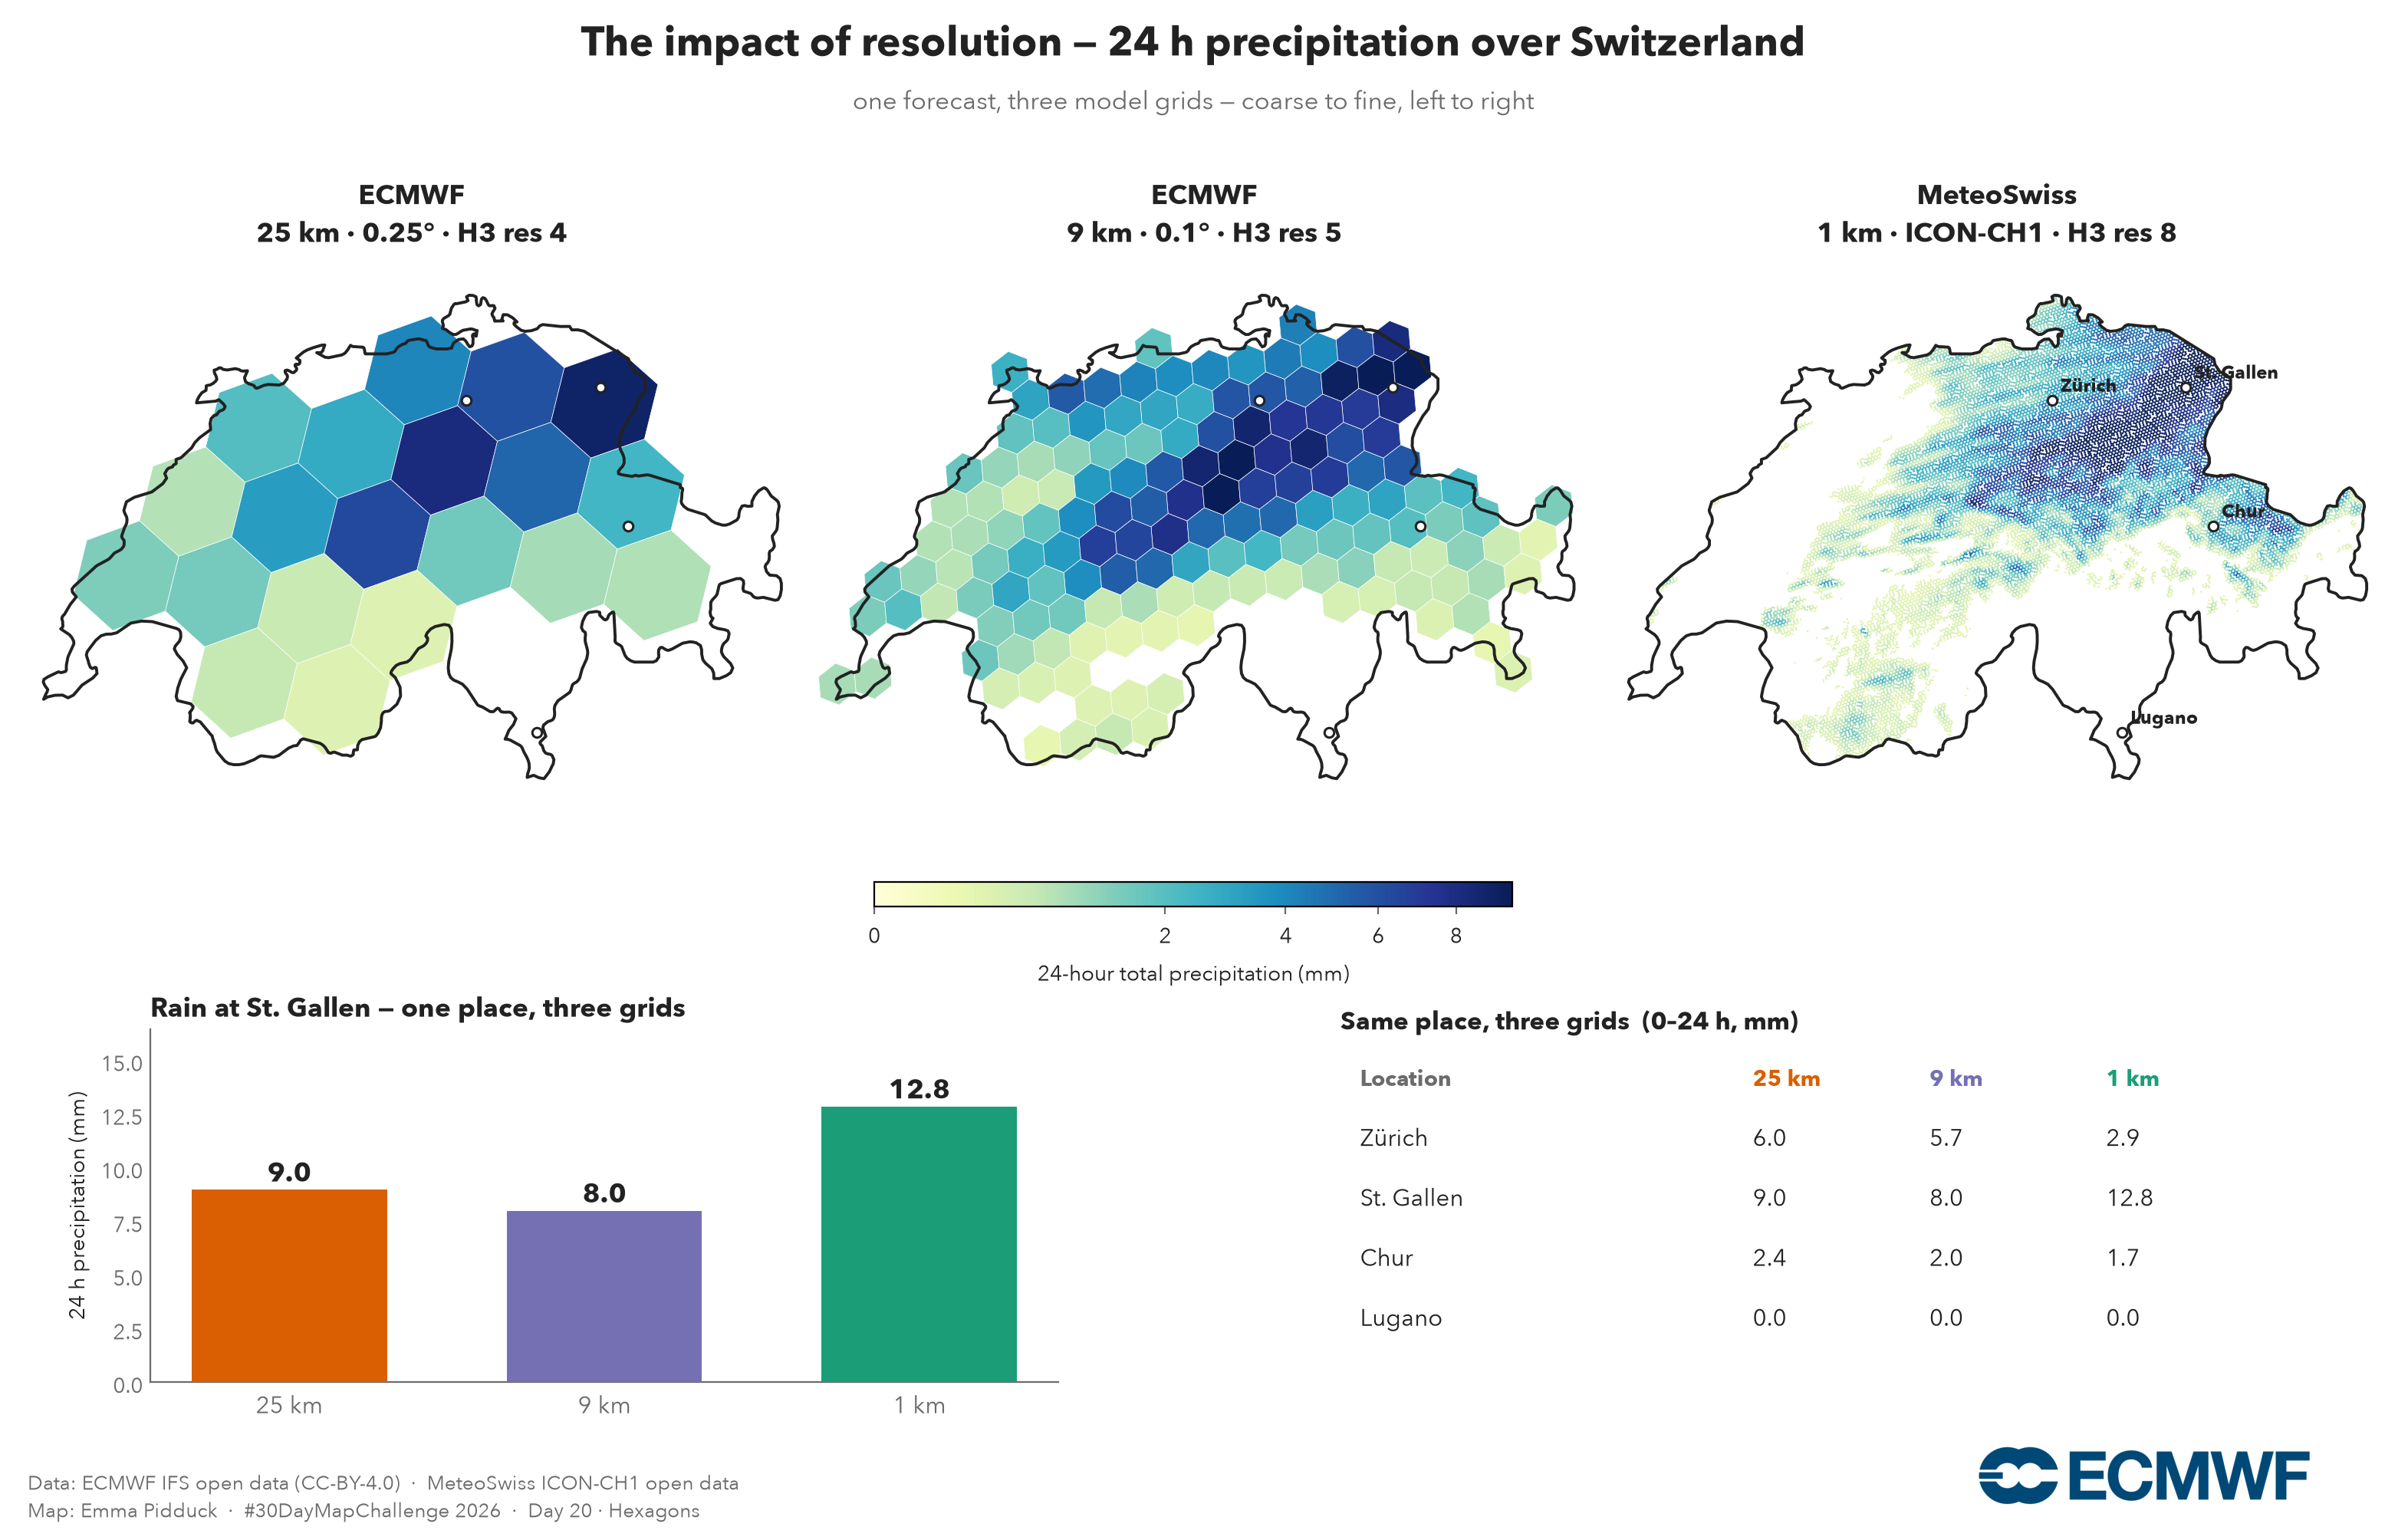

In [7]:
cmap = plt.get_cmap("YlGnBu")
VMAX = np.percentile(np.concatenate(list(vals.values())), 97)
norm = PowerNorm(0.5, vmin=0.0, vmax=max(VMAX, 1.0))
def polys(cs): return [[(p[1], p[0]) for p in h3.cell_to_boundary(c)] for c in cs]
def _val(cs, vs, lat, lon, res):
    m = dict(zip(cs.tolist(), vs.tolist())); c = h3.latlng_to_cell(lat, lon, res)
    if c in m: return m[c]
    for k in (1, 2, 3, 4):
        n = [m[x] for x in h3.grid_disk(c, k) if x in m]
        if n: return float(np.mean(n))
    return np.nan

proj = ccrs.AlbersEqualArea(central_longitude=8.2, central_latitude=46.8)
fig = plt.figure(figsize=(16, 10), dpi=200); fig.patch.set_facecolor(BG)
PAN = [("c25", "ECMWF", "25 km · 0.25° · H3 res 4", BG, 0.020),
       ("c9",  "ECMWF", "9 km · 0.1° · H3 res 5", BG, 0.343),
       ("c1",  "MeteoSwiss", "1 km · ICON-CH1 · H3 res 8", "none", 0.666)]
for key, lab, sub, ecol, x0 in PAN:
    ax = fig.add_axes([x0, 0.46, 0.323, 0.40], projection=proj)
    ax.set_facecolor(BG); ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    try: ax.spines["geo"].set_visible(False)
    except Exception: pass
    cs, vs = cells[key], vals[key]; wet = vs >= DRY
    ax.add_collection(PolyCollection(polys(cs[wet]), transform=ccrs.PlateCarree(),
                      facecolors=cmap(norm(vs[wet])), edgecolors=ecol, linewidths=0.25))
    ax.add_geometries([ch_geom], crs=ccrs.PlateCarree(), facecolor="none",
                      edgecolor=INK, linewidth=1.4, zorder=5)
    for name, lat, lon in CITIES:
        ax.plot(lon, lat, "o", ms=4.5, mfc="#fff", mec=INK, mew=1.1,
                transform=ccrs.PlateCarree(), zorder=6)
        if key == "c1":
            ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points",
                        transform=ccrs.PlateCarree(), fontsize=8.5, fontweight="bold", color=INK)
    ax.set_title(f"{lab}\n{sub}", color=INK, fontsize=13, pad=6, fontweight="bold")

cax = fig.add_axes([0.37, 0.41, 0.26, 0.016])
cb = fig.colorbar(mcm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
cb.set_ticks([0, 2, 4, 6, 8]); cb.set_label(f"{ACC}-hour total precipitation (mm)", color=INK, fontsize=10)
cb.ax.xaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)

# one wet place across the three grids
axB = fig.add_axes([0.075, 0.10, 0.37, 0.23]); axB.set_facecolor(BG)
PLACE = CITIES[1]
pv = [_val(cells["c25"], vals["c25"], PLACE[1], PLACE[2], 4),
      _val(cells["c9"],  vals["c9"],  PLACE[1], PLACE[2], 5),
      _val(cells["c1"],  vals["c1"],  PLACE[1], PLACE[2], 8)]
axB.bar(range(3), pv, color=[C25, C9, C1], width=0.62, zorder=3)
for i, v in enumerate(pv):
    axB.text(i, v + max(pv) * 0.03, f"{v:.1f}", ha="center", color=INK, fontsize=13, fontweight="bold")
axB.set_xticks(range(3)); axB.set_xticklabels(["25 km", "9 km", "1 km"], color=INK, fontsize=11)
axB.set_ylim(0, max(pv) * 1.28); axB.set_ylabel(f"{ACC} h precipitation (mm)", color=INK, fontsize=10)
axB.set_title(f"Rain at {PLACE[0]} — one place, three grids", color=INK, fontsize=12.5,
              fontweight="bold", loc="left")
axB.tick_params(colors=MUT, length=0)
for s in ("top", "right"): axB.spines[s].set_visible(False)
for s in ("left", "bottom"): axB.spines[s].set_color(MUT)

# call-out table
axT = fig.add_axes([0.56, 0.10, 0.40, 0.23]); axT.axis("off")
axT.text(0.0, 1.0, f"Same place, three grids  (0–{ACC} h, mm)", fontsize=12, fontweight="bold",
         color=INK, transform=axT.transAxes)
for txt, x, col in [("Location", 0.02, MUT), ("25 km", 0.42, C25), ("9 km", 0.60, C9), ("1 km", 0.78, C1)]:
    axT.text(x, 0.84, txt, fontsize=10.5, color=col, fontweight="bold", transform=axT.transAxes)
for i, (name, lat, lon) in enumerate(CITIES):
    y = 0.84 - 0.17 * (i + 1)
    row = [_val(cells["c25"], vals["c25"], lat, lon, 4),
           _val(cells["c9"],  vals["c9"],  lat, lon, 5),
           _val(cells["c1"],  vals["c1"],  lat, lon, 8)]
    axT.text(0.02, y, name, fontsize=11, color=INK, transform=axT.transAxes)
    for x, v in zip((0.42, 0.60, 0.78), row):
        axT.text(x, y, f"{v:.1f}", fontsize=11, color=INK, transform=axT.transAxes)

fig.text(0.5, 0.965, "The impact of resolution — 24 h precipitation over Switzerland",
         ha="center", color=INK, fontsize=19, fontweight="bold")
fig.text(0.5, 0.93, "one forecast, three model grids — coarse to fine, left to right",
         ha="center", color=MUT, fontsize=12)
fig.text(0.025, 0.03, "Data: ECMWF IFS open data (CC-BY-4.0)  ·  MeteoSwiss ICON-CH1 open data",
         color=MUT, fontsize=9.5)
fig.text(0.025, 0.012, f"Map: {AUTHOR}  ·  #30DayMapChallenge 2026  ·  Day 20 · Hexagons",
         color=MUT, fontsize=9.5)

logo = "assets/ECMWF_Core_Logo_RGB.png"
if os.path.exists(logo):
    img = mpimg.imread(logo); ar = img.shape[1] / img.shape[0]
    h = 0.038; w = h * ar * (fig.get_figheight() / fig.get_figwidth())
    la = fig.add_axes([0.955 - w, 0.02, w, h]); la.imshow(img); la.axis("off")

fig.savefig("day20_hexagons.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

MeteoSwiss **ICON-CH1** runs to 33 h, so the window is capped at ≤ 33 h (24 h here). For a
longer range you would switch to **ICON-CH2** (2.1 km, 120 h). ECMWF Open Data is published at
0.25° and 0.1°; `resol` selects the grid.

**Saved:** `day20_hexagons.png` — ready to post.